In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
def knots_generation(a,b,K):

    assert K >=2 , "K must be a positive integer."
    assert a < b, "Lower bound a must be less than upper bound b."
    res=np.linspace(a, b, K)
    return res

knots_gen = knots_generation(-10.5, -8, 7)
knots_gen


array([-10.5       , -10.08333333,  -9.66666667,  -9.25      ,
        -8.83333333,  -8.41666667,  -8.        ])

In [3]:
def K_gen(knots):
    knots = np.sort(knots)
    K=len(knots)-1
    Q=np.zeros((K+1,K-1))
    R=np.zeros((K-1,K-1))
    for k in range(K-1):
        h0=knots[k+1]-knots[k]
        h1=knots[k+2]-knots[k+1]
        Q[k,k]=1/h0
        Q[k+1,k]=-1/h0 - 1/h1
        Q[k+2,k]=1/h1
        R[k,k]=(h0+h1)/3
        if k<K-2:
            R[k+1,k]=h1/6
        if k>0:
            R[k-1,k]=h0/6 
    return Q @ np.linalg.solve(R, Q.T)

K_penalty= K_gen(knots_gen)
print(K_penalty)
print("Eigenvalues of K_penalty:", np.linalg.eigvals(K_penalty))
print("Is K_penalty positive definite?", np.all(np.linalg.eigvals(K_penalty) >= -1e-10))  # Allowing for numerical precision issues

[[ 2.22247385e+01 -5.04044308e+01  3.57297231e+01 -9.57046154e+00
   2.55212308e+00 -6.38030769e-01  1.06338462e-01]
 [-5.04044308e+01  1.36538585e+02 -1.31434338e+02  5.74227692e+01
  -1.53127385e+01  3.82818462e+00 -6.38030769e-01]
 [ 3.57297231e+01 -1.31434338e+02  1.93961354e+02 -1.46747077e+02
   6.12509538e+01 -1.53127385e+01  2.55212308e+00]
 [-9.57046154e+00  5.74227692e+01 -1.46747077e+02  1.97789538e+02
  -1.46747077e+02  5.74227692e+01 -9.57046154e+00]
 [ 2.55212308e+00 -1.53127385e+01  6.12509538e+01 -1.46747077e+02
   1.93961354e+02 -1.31434338e+02  3.57297231e+01]
 [-6.38030769e-01  3.82818462e+00 -1.53127385e+01  5.74227692e+01
  -1.31434338e+02  1.36538585e+02 -5.04044308e+01]
 [ 1.06338462e-01 -6.38030769e-01  2.55212308e+00 -9.57046154e+00
   3.57297231e+01 -5.04044308e+01  2.22247385e+01]]
Eigenvalues of K_penalty: [5.15712832e+02 2.63137258e+02 9.69129595e+01 2.44019415e+01
 3.07390063e+00 4.26475578e-14 1.97395589e-15]
Is K_penalty positive definite? True


In [4]:
eigenvalues, eigenvectors = np.linalg.eigh(K_penalty)
coeff = np.random.normal(0, 1, size=7)
eps = np.zeros(7)
for i in range(7):
    if i<=1:
        eps += eigenvectors[:,i]*coeff[i]*0.01
    else:
        eps += eigenvectors[:,i]*coeff[i]/np.sqrt(eigenvalues[i])
eps

array([-0.37447408, -0.03833566,  0.21599469,  0.40606147,  0.23686483,
       -0.08415612, -0.33701134])

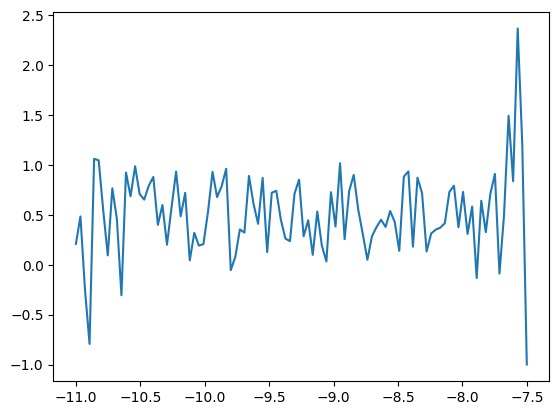

In [5]:
from scipy.interpolate import CubicSpline
def spline(natural_spline, knots, h): 
    # natural_spline = CubicSpline(knots, g, bc_type='natural')

    h_array = np.asarray(h, dtype=float)
    scalar_input = h_array.ndim == 0
    h_array = np.atleast_1d(h_array)

    result = np.empty_like(h_array, dtype=float)

    left_mask = h_array < knots[0]
    right_mask = h_array > knots[-1]
    inside_mask = ~(left_mask | right_mask)

    left_value = natural_spline(knots[0])
    left_slope = natural_spline(knots[0], nu=1)

    right_value = natural_spline(knots[-1])
    right_slope = natural_spline(knots[-1], nu=1)

    result[left_mask] = (
        left_value
        + left_slope * (h_array[left_mask] - knots[0])
    )

    result[right_mask] = (
        right_value
        + right_slope * (h_array[right_mask] - knots[-1])
    )

    result[inside_mask] = natural_spline(h_array[inside_mask])

    if scalar_input:
        return result[0]

    return result

spline_values = [spline(CubicSpline(knots_gen, np.random.rand(len(knots_gen)), bc_type='natural'), knots_gen, h) for h in np.linspace(-11, -7.5, 100)]
plt.plot(np.linspace(-11, -7.5, 100), spline_values)


g.T @ K_penalty @ g: 3.695330499930984e-12


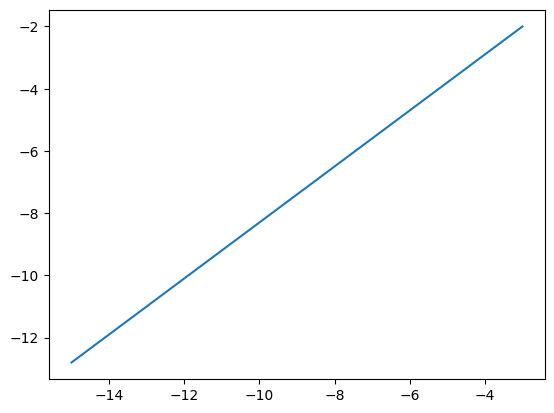

In [6]:
g = 0.7+0.9*knots_gen
spline_func = CubicSpline(knots_gen, g, bc_type='natural')
linear_values = [spline(spline_func, knots_gen, h) for h in np.linspace(-15, -3, 100)]
print("g.T @ K_penalty @ g:", g.T @ K_penalty @ g)
plt.plot(np.linspace(-15, -3, 100), linear_values)


### Equation de rendements

$y_t = \alpha + \beta x_t + \exp(h_t/2) v_t$

avec :

- $\alpha$ : Moyenne des rendements (ex : 0.1, ie 10% de rendements journaliers)
- $x_t \sim \mathcal{U}(-0.05,0.05)$
- $\beta$ : Le coeff de sensibilité du rendement à la variable $x_t$ (ex : 0.9). Augmenter beta augmente la variabilité du rendement observé y.
- $\exp(h_t/2) v_t$ : Composante de vol stochastique avec $v_t \sim \mathcal{N}(0,1)$

### Equation de volatilité 

La forme d'un processus autorégressif linéaire classique est : 

$h_{t+1} = \mu (1-\phi) + \phi h_t + \sigma w_t$

avec :
- $\mu$ : la moyenne à long terme
- $\phi$ : le retour à la moyenne, si $\phi$ proche de 0, on retourne très vite a la moyenne, si $\phi$ proche de 1 on retourne plus lentement
- $w_t \sim \mathcal{N}(0,1)$

Dans notre cas, on remplace $\mu = \mu(h_t) = -10 +1.5 cdf(.)$ => La moyenne dépend de l'état.

- $cdf$ est la fonction de répartition de la loi normale
- Quand la vol est basse (ie $h_t \to -\infty$) cdf tend vers 0 donc la moyenne cible est $\mu(h_t) = -10$
- Quand la vol est haute (ie $h_t \to \infty$) cdf tend vers 1 donc la moyenne cible est $\mu(h_t) = -10+1.5 = -8.5$
- Au numérateur de la cdf, on a $h_t - (-9.25)$ donc quand la vol vaut -9.25, on a cdf(0) = 0.5 donc $\mu(-9.25) = 10+1.5\times 0.5 = -9.25$
- Au dénominateur de la cdf, on a $ 0.5 \sigma / \sqrt{(1-\phi ^2)}$
    - Pour un processus AR(1) stationnaire : $h_{t+1} = c + \phi h_t + \sigma Z_t$, la variance est $Var(h_t) = \dfrac{\sigma ^2}{1-\phi^2}$ donc $\sigma_h = \dfrac{\sigma}{\sqrt{1-\phi^2}}$ 
    - On multiplie par 0.5 pour que la variable d'entrée de la cdf soit adimensionnelle

In [7]:
def mh_simu(h_prev,sigma_w=0.25, phi=0.7,mu=-9.25):
    sigma_h = sigma_w/np.sqrt(1-phi**2)
    scale = 0.5 * sigma_h
    cdf_arg = (h_prev - mu)/scale
    mu_h = -10 + 1.5*norm.cdf(cdf_arg)
    h = mu_h*(1-phi) + phi*h_prev

    return h

In [8]:
def mh_spline(h_prev,sigma_w=0.25, phi=0.7,mu=-9.25,knots=knots_gen):
    sigma_h = sigma_w/np.sqrt(1-phi**2)
    scale = 0.5 * sigma_h
    cdf_arg = (knots - mu)/scale
    mu_h = -10 + 1.5*norm.cdf(cdf_arg)
    g = mu_h*(1-phi) + phi*knots 
    spline_func = CubicSpline(knots, g, bc_type='natural')

    return spline(spline_func, knots, h_prev)

g.T @ K_penalty @ g: 3.4707419980604245e-06


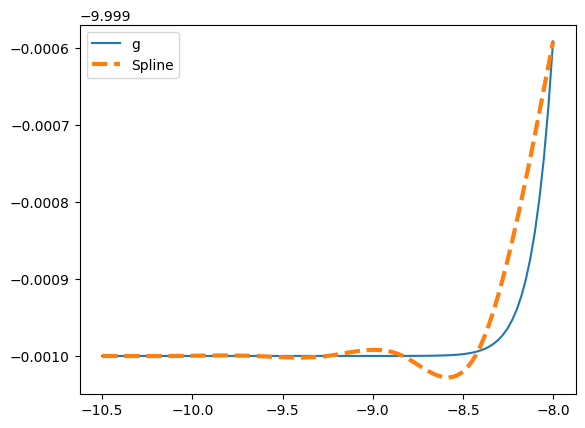

In [9]:
grid = np.linspace(-10.5, -8, 100)
g = -10 + 1.5 * norm.cdf(
    (grid - (-9.25)) / (0.5 * (0.25 / np.sqrt(1 - 0.7**2))) * (1 - 0.7) + 0.7*grid
)

g_at_knots = -10 + 1.5 * norm.cdf(
    (knots_gen - (-9.25)) / (0.5 * (0.25 / np.sqrt(1 - 0.7**2))) * (1 - 0.7) + 0.7*knots_gen
)
spline_func = CubicSpline(knots_gen, g_at_knots, bc_type='natural')
spline_values = [spline(spline_func, knots_gen, h) for h in grid]

print("g.T @ K_penalty @ g:", g_at_knots.T @ K_penalty @ g_at_knots)

plt.plot(grid, g, label="g")
plt.plot(grid, spline_values, label="Spline", linestyle='--', linewidth=3)
plt.legend()
plt.show()

In [10]:
def data_generating_process(alpha=0.01,beta=0.9, sigma_w=0.25, phi=0.7, T=1000, mu=-9.25):

    v = np.random.normal(0,1,size=T)
    x = np.random.uniform(-0.05, 0.05, size=T)
    w = np.random.normal(0, 1, size=T)

    h = np.zeros(T)
    y = np.zeros(T)

    h[0] = mu
    
    for t in range(T-1):
        y[t] = alpha+beta*x[t] + np.exp(h[t]/2)*v[t]
        h[t+1] = mh_simu(h[t], sigma_w, phi, mu=mu)  + w[t]*sigma_w
    y[T-1] = alpha+beta*x[T-1] + np.exp(h[T-1]/2)*v[T-1]

    return y, h, x

y, h, x = data_generating_process(T=1000, phi=0.7)

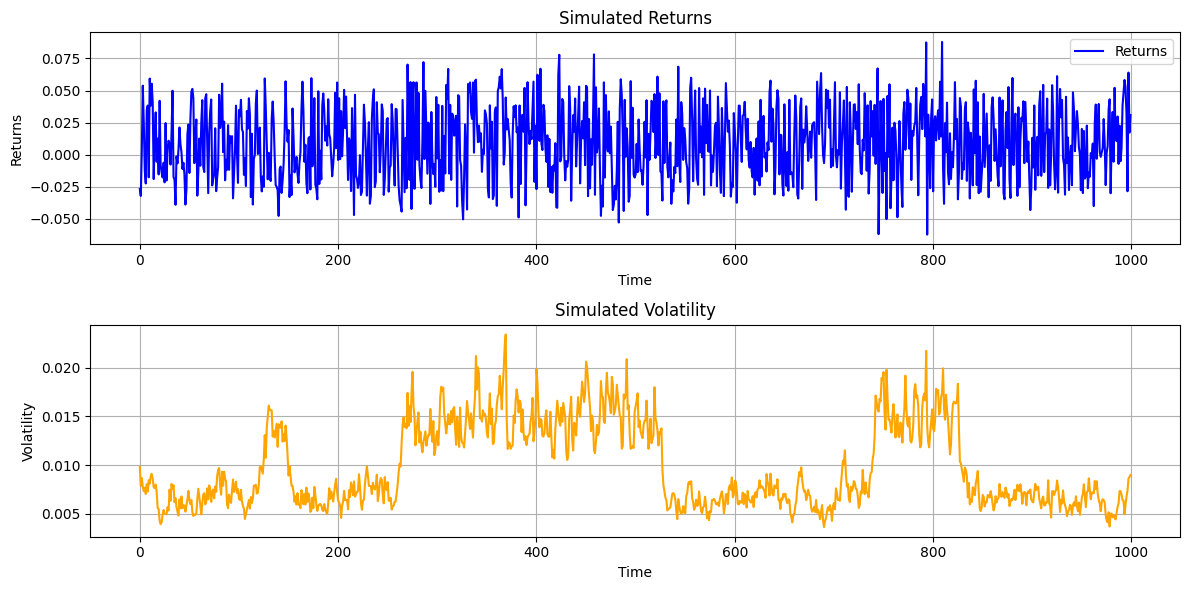

In [11]:
plt.figure(figsize=(12, 6))
plt.subplot(2, 1, 1)
plt.plot(y, label='Returns', color='blue')
plt.title('Simulated Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()
plt.grid()
plt.subplot(2, 1, 2)
plt.plot(np.exp(h/2), label='Volatility', color='orange')
plt.title('Simulated Volatility')
plt.xlabel('Time')
plt.ylabel('Volatility')
plt.grid()
plt.tight_layout()


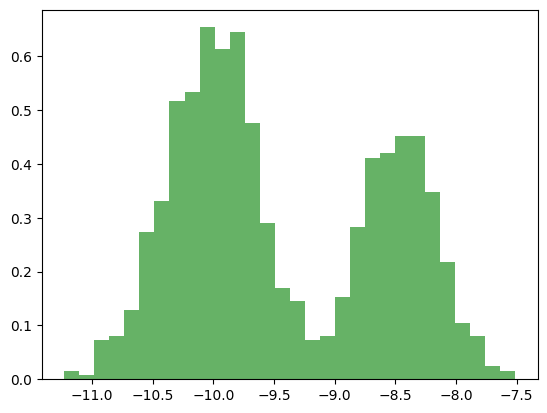

In [12]:
plt.hist(h, bins=30, density=True, alpha=0.6, color='g')
plt.show()

### Bootstrap filter

1) Initialisation :
    - On initialise un vecteur de poids (taille M), d'increments(T), de volatilité (T) et on initialise les particules suivant une loi normale de moyenne -9.25 et d'écart type sigma (M).

2) Boucle $t=0,...,T$ :
    - Propagation : Chaque particule avance selon la transition : $\tilde{h_t}^{(i)} = m_h(h_{t-1}^{(i)}) + \sigma w_t$.
    - Poids (log) : Pour chaque particule, on calcule $log(p(y_t | \tilde{h_t}^{(i)}))$. On sait que $y_t = \alpha + \exp(h_t/2) v_t$ donc $\mathbb{E}(y_t | h_t) = \alpha$. 
    $Var(y_t | h_t) = \exp(h_t)$. Donc $p(y_t | h_t) = \dfrac{1}{\sqrt{2\pi e^{h_t}}} \exp(-\frac{(y_t - \alpha)^2}{2e^{h_t}}) $
    - Incréments de vraisemblance : $p(y_t | y_{1:t−1}) ≈ (1/M) Σ_i w_t⁽ⁱ⁾$ (on passe en log dans le code). C'est la densité de l'observation du jour. Cela mesure à quel point le model s'attendait-il au rendement observé aujourd'hui. Dans le code on utilise un trick pour ne pas qu'on ai d'overflow : on soustrait par le poids maximum dans l'exponentielle et on l'additionne en dehors du log car l'exponentielle ne peut pas calculer des valeurs avec de gros exposants, même si le resultat finale est petit.
    - Normalisation des poids : On divise chaque poids par la somme des poids (softmax). On utilise le même trick du max pour ne pas avoir d'overflow si on a des poids avec de grosses valeurs.
    - Réechantillonnage : On tire M particules selon les poids et on remplace les particules par les particules selectionnées qui repartent toutes avec un poids 1/M.
    - On stocke notre volatilité prédite comme la moyenne des particules après réechantillonnage

On calcule la log likelihood comme la somme des incréments : $p(y_1, …, y_T) = p(y_1) × p(y_2 | y_1) × p(y_3 | y_1, y_2) × … × p(y_T | y_1, …, y_{T−1})$

In [13]:
def compute_y_centered(y, x, alpha, beta):
    if x is not None:
        y_centered = y - (alpha + beta * x)
    else:
        y_centered = y - alpha
    return y_centered

def bootstrap_filter(y_centered, sigma_w, initial_mean, initial_std, m_h:callable, M):
    T = len(y_centered)
    weights = np.zeros(M)
    increments = np.zeros(T)
    h=np.zeros(T)
    particles = np.random.normal(initial_mean, initial_std, size=M)
    for t in range(T):
        particles = m_h(h_prev=particles) + np.random.normal(0, sigma_w, size=M)
        weights = -0.5*np.log(2*np.pi) -0.5*particles - (y_centered[t])**2 / (2*np.exp(particles))
        increments[t] = np.log(np.sum(np.exp(weights - np.max(weights)))) +  np.max(weights) - np.log(M)
        weights = np.exp(weights - np.max(weights))/np.sum(np.exp(weights - np.max(weights)))
        if np.nan in weights or np.sum(weights) == 0:
            print(f"Warning: Weights are NaN or sum to zero at time {t}")
            return -np.inf, increments, h  
        particles = np.random.choice(particles, size=M, p=weights)
        h[t] = np.mean(particles)
    log_likelihood = np.sum(increments)
    return log_likelihood, increments, h


y_centered = compute_y_centered(y, x=x, alpha=0.01, beta=0.9)
log_likelihood, increments, h_hat = bootstrap_filter(y_centered, sigma_w=0.25, initial_mean=-9.25, initial_std=0.7, m_h=mh_simu, M=1000)
print(f"Log likelihood: {log_likelihood}")
print(f"MSE between true h and estimated h_hat: {np.mean((h - h_hat)**2)}")
  

Log likelihood: 3216.134799262255
MSE between true h and estimated h_hat: 0.20195321699337096


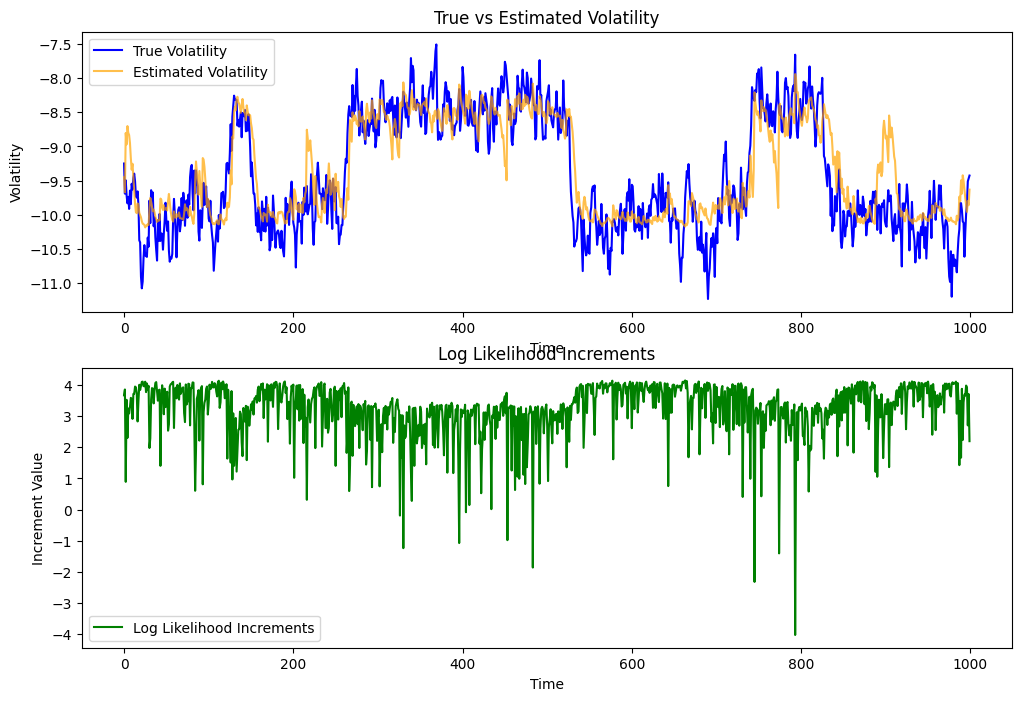

In [14]:
plt.figure(figsize=(12, 8))
plt.subplot(2, 1, 1)
plt.plot(h, label='True Volatility', color='blue')
plt.plot(h_hat, label='Estimated Volatility', color='orange', alpha=0.7)
plt.title('True vs Estimated Volatility')
plt.xlabel('Time')
plt.ylabel('Volatility')
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(increments, label='Log Likelihood Increments', color='green')
plt.title('Log Likelihood Increments')
plt.xlabel('Time')
plt.ylabel('Increment Value')
plt.legend()
plt.show()

## PMMH SV classique

On initialise nos parametres $\theta = (\alpha, \beta, \mu, \phi, \log(\sigma^2))$. On calcule la vraisemblance en utilisant notre filtre bootstrap sur les parametres initialisés. On pose le prior : $\alpha, \beta, \phi, \log(\sigma^2) \sim \mathcal{N}(0,100)$. Donc le log prior joint est proportionel à $− (α² + β² + μ² + φ² + (log σ²)²) / 200$. 

Pour chaque itération, on ajoute du bruit à nos parametres, et on recalcule la vraisemblance avec le filtre bootstrap, ainsi que le prior.

Le ratio d'acceptation est : $\alpha(\theta^*, \theta) = \min{(\dfrac{p(\theta^*)p(y_t | \theta^*) q(\theta, \theta^*)}{p(\theta)p(y_t | \theta) q(\theta^*, \theta)},1)}$. Or nos $q$ sont des loi normales donc symétrique. On peut donc simplifier notre ratio. On passe en log et on a $\log(\alpha(\theta^*, \theta)) = \log(p(\theta^*))+\log(p(y_t | \theta^*)) - \log(p(\theta))-\log(p(y_t | \theta)) $.

In [ ]:
from sklearn.linear_model import LinearRegression

def classical_sv_pmmh(y,x=None, warmup_iterations=100, iterations=100):
    if x is not None:
        reg = LinearRegression().fit(x.reshape(-1, 1), y)
        alpha = reg.intercept_
        beta = reg.coef_[0]
        mu  = 2 * np.log((x*beta + alpha - y).std())
    else:
        alpha = 0.01    
        mu  = 2 * np.log((alpha - y).std())
    phi = 0.5
    log_sigma2 = -3
    parameters = {'alpha': alpha, 'mu': mu, 'phi': phi, 'log_sigma2': log_sigma2, 'beta': beta} if x is not None else {'alpha': alpha, 'mu': mu, 'phi': phi, 'log_sigma2': log_sigma2}
    steps = {'alpha': 0.0003, 'mu': 0.01, 'phi': 0.01, 'log_sigma2': 0.1, 'beta': 0.01} if x is not None else {'alpha': 0.0003, 'mu': 0.01, 'phi': 0.01, 'log_sigma2': 0.1}
    history_parameters = {'alpha': [alpha], 'mu': [mu], 'phi': [phi], 'log_sigma2': [log_sigma2], 'beta': [beta]} if x is not None else {'alpha': [alpha], 'mu': [mu], 'phi': [phi], 'log_sigma2': [log_sigma2]}
    
    def m_h_init(h_prev):
        return parameters['mu']*(1-parameters['phi']) + parameters['phi']*h_prev
    std = np.sqrt(np.exp(parameters['log_sigma2']))/np.sqrt(1-parameters['phi']**2)
    y_centered = compute_y_centered(y, x=x, alpha=parameters['alpha'], beta=parameters.get('beta', 0))
    log_likelihood,_,_ = bootstrap_filter(y_centered, sigma_w=np.sqrt(np.exp(parameters['log_sigma2'])), initial_mean=parameters['mu'], initial_std=std, m_h=m_h_init, M=1000)
    log_prior = 0
    for parameter in parameters:
        log_prior += -(parameters[parameter]**2)/200

    likelihood_history = [log_likelihood]
    for iteration in range(warmup_iterations + iterations):
        candidate_params = {}
        for param in parameters:
            candidate_params[param] = np.random.normal(parameters[param], steps[param])
        if abs(candidate_params['phi']) < 1:
            def m_h_hat(h_prev):
                return candidate_params['mu']*(1-candidate_params['phi']) + candidate_params['phi']*h_prev
            std_hat = np.sqrt(np.exp(candidate_params['log_sigma2']))/np.sqrt(1-candidate_params['phi']**2)
            y_centered_hat = compute_y_centered(y, x=x, alpha=candidate_params['alpha'], beta=candidate_params.get('beta', 0))
            new_log_likelihood,_,_ = bootstrap_filter(y_centered_hat, sigma_w=np.sqrt(np.exp(candidate_params['log_sigma2'])), initial_mean=candidate_params['mu'], initial_std=std_hat, m_h=m_h_hat, M=1000)
            new_log_prior = 0
            for param in parameters:
                new_log_prior += -(parameters[param]**2)/200
            log_ratio = new_log_likelihood + new_log_prior - log_likelihood - log_prior
            if np.log(np.random.rand()) < log_ratio :
                log_likelihood, log_prior = new_log_likelihood, new_log_prior
                
                for param in parameters:
                    parameters[param] = candidate_params[param]
        for param in parameters:
            history_parameters[param].append(parameters[param])
        likelihood_history.append(log_likelihood)
        if iteration % 100 == 0:
            disp = f" {iteration + 1}: Log likelihood = {log_likelihood}, " +", ".join([f"{param} = {parameters[param]}" for param in parameters])
            print(disp)

    for param in parameters:
        parameters[param] = np.mean(history_parameters[param][warmup_iterations:], axis=0)
    y_centered = compute_y_centered(y, x=x, alpha=parameters['alpha'], beta=parameters.get('beta', 0))
    _,_,h_hat = bootstrap_filter(y_centered, initial_mean=parameters['mu'], initial_std=np.sqrt(np.exp(parameters['log_sigma2'])/(1-parameters['phi']**2)), sigma_w=np.sqrt(np.exp(parameters['log_sigma2'])), m_h=lambda h_prev: parameters['mu']*(1-parameters['phi']) + parameters['phi']*h_prev, M=1000)
    return parameters, h_hat, history_parameters, likelihood_history
parameters_classical, h_hat_classical, parameters_history_classical, likelihood_history_classical = classical_sv_pmmh(y,x, warmup_iterations=500, iterations=1000)


In [ ]:
def plot_trace(parameters_history, likelihood_history):
    n = len(parameters_history)+1
    plt.figure(figsize=(12, 10))
    if "g" in parameters_history:
        del parameters_history["g"]
    cols = np.ceil(np.sqrt(n)).astype(int)
    rows = np.ceil(n / cols).astype(int)
    for i, param in enumerate(parameters_history):
        plt.subplot(rows, cols, i + 1)
        plt.plot(parameters_history[param], label=param)
        plt.title(f'Trace of {param}')
        plt.xlabel('Iteration')
        plt.ylabel(param)
    plt.subplot(rows, cols, n)
    plt.plot(likelihood_history, label='Log Likelihood')
    plt.title('Trace of Log Likelihood')
    plt.xlabel('Iteration')
    plt.ylabel('Log Likelihood')
    plt.tight_layout()
    plt.show()
plot_trace(parameters_history_classical, likelihood_history_classical)

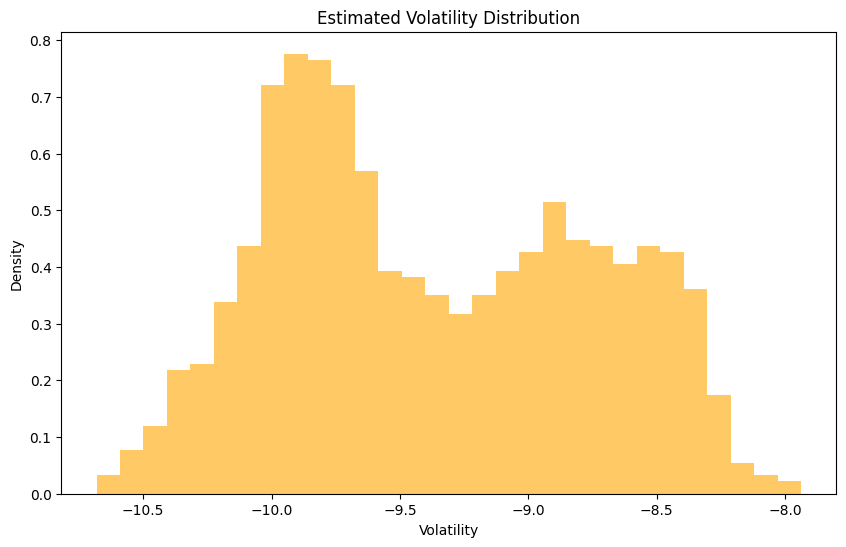

In [77]:
plt.figure(figsize=(10, 6))
plt.hist(h_hat_classical, label='Estimated Volatility', color='orange', bins=30, density=True, alpha=0.6)
plt.title('Estimated Volatility Distribution')
plt.xlabel('Volatility')
plt.ylabel('Density')
plt.show()

In [ ]:
def parametric_sv_pmmh(y,x=None, K=6,sigma_e=0.01, kernel_width=0.01, warmup_iterations=1000, iterations=1000):
    print("Initializing using classical SV PMMH...")
    parameters,h_hat,_,_  = classical_sv_pmmh(y,x, warmup_iterations=200, iterations=200)
    
    a,b = np.quantile(h_hat, [0.01, 0.99])
    knots = np.linspace(a, b, K+1)
    K_penalty = K_gen(knots)
    eigenvalues, eigenvectors = np.linalg.eigh(K_penalty)
    g = parameters["mu"]*(1-parameters["phi"]) + parameters["phi"]*knots
    initial_mean = parameters["mu"]
    initial_std = np.sqrt(np.exp(parameters["log_sigma2"])/(1-parameters["phi"]**2))
    lamb = 0.01
    parameters.pop('mu', None)
    parameters.pop('phi', None)
    log_prior = - 0.5*lamb*g.T @ K_penalty @ g
    for param in parameters:
        log_prior += -(parameters[param]**2)/200
    
    spline_func = CubicSpline(knots, g, bc_type='natural')
    m_h = lambda h_prev: spline(spline_func, knots, h_prev)
    y_centered = compute_y_centered(y, x=x, alpha=parameters['alpha'], beta=parameters.get('beta', 0))
    log_likelihood,_,_ = bootstrap_filter(y_centered, initial_mean=initial_mean, initial_std=initial_std, sigma_w=np.sqrt(np.exp(parameters['log_sigma2'])), m_h=m_h, M=1000)
        
    history_likelihood = [log_likelihood]
    history_parameters = {"g":[g]}
    for param in parameters:
        history_parameters[param] = [parameters[param]]
    steps = {'alpha': 0.0003, 'log_sigma2': 0.1, 'beta': 0.01} if x is not None else {'alpha': 0.0003, 'log_sigma2': 0.1}
    parameters_block2 = set(('log_sigma2', 'g'))
    accept_count = 0
    accept_count_g = 0

    for iteration in range(warmup_iterations + iterations):
        candidate_params = {}
        for param in parameters:
            if param not in parameters_block2:
                candidate_params[param] = np.random.normal(parameters[param], steps[param])
            else:
                candidate_params[param] = parameters[param]

        m_h_hat = lambda h_prev: spline(spline_func, knots, h_prev)
        log_prior_hat = -0.5*lamb*g.T @ K_penalty @ g
        for param in parameters:
            log_prior_hat += -(candidate_params[param]**2)/200
        y_centered_hat = compute_y_centered(y, x=x, alpha=candidate_params['alpha'], beta=candidate_params.get('beta', 0))
        new_log_likelihood,_,_ = bootstrap_filter(y_centered_hat, initial_mean=initial_mean, initial_std=initial_std, sigma_w=np.sqrt(np.exp(parameters['log_sigma2'])), m_h=m_h_hat, M=1000)
        log_ratio = new_log_likelihood + log_prior_hat - log_likelihood - log_prior
        if np.log(np.random.rand()) < log_ratio :
            log_likelihood, log_prior = new_log_likelihood, log_prior_hat
            for param in parameters:
                parameters[param] = candidate_params[param]
            accept_count += 1


        coeff = np.random.normal(0, 1, K+1)
        eps = np.zeros(K+1)
        for i in range(K+1):
            if i<=1:
                eps += eigenvectors[:,i]*coeff[i]*kernel_width
            else:
                eps += eigenvectors[:,i]*coeff[i]*sigma_e/np.sqrt(eigenvalues[i])
        g_hat = g + eps
        log_sigma2_hat = np.random.normal(parameters['log_sigma2'], steps['log_sigma2'])
        log_prior_hat = -(log_sigma2_hat**2)/200 - 0.5*lamb*g_hat.T @ K_penalty @ g_hat
        for param in parameters:
            if param not in parameters_block2:
                log_prior_hat += -(parameters[param]**2)/200
        
        spline_func_hat = CubicSpline(knots, g_hat, bc_type='natural')
        spline_func_hat_derivative = spline_func_hat.derivative()
        if abs(spline_func_hat_derivative(knots[0])) <= 1 and abs(spline_func_hat_derivative(knots[-1])) <= 1:
            m_h_hat = lambda h_prev: spline(spline_func_hat, knots, h_prev)
            y_centered_hat = compute_y_centered(y, x=x, alpha=parameters['alpha'], beta=parameters.get('beta', 0))
            new_log_likelihood,_,_ = bootstrap_filter(y_centered_hat, initial_mean=initial_mean, initial_std=initial_std, sigma_w=np.sqrt(np.exp(log_sigma2_hat)), m_h=m_h_hat, M=1000)
            log_ratio = new_log_likelihood + log_prior_hat - log_likelihood - log_prior
            if np.log(np.random.rand()) < log_ratio :
                log_likelihood, log_prior = new_log_likelihood, log_prior_hat
                g = g_hat
                parameters['log_sigma2'] = log_sigma2_hat
                spline_func = spline_func_hat
                accept_count_g += 1
        history_parameters["g"].append(g)
        for param in parameters:
            history_parameters[param].append(parameters[param])
        history_likelihood.append(log_likelihood)
        if iteration % 100 == 0:
            disp = f" {iteration + 1}: Log likelihood = {log_likelihood}, " +", ".join([f"{param} = {parameters[param]}" for param in parameters])
            print(disp)
    history_parameters['sigma'] = np.sqrt(np.exp(np.array(history_parameters['log_sigma2'])))
    for param in parameters:
        parameters[param] = np.mean(history_parameters[param][warmup_iterations:], axis=0)

    parameters['g'] = np.mean(history_parameters['g'][warmup_iterations:], axis=0)
    parameters['knots'] = knots
    parameters['initial'] = (initial_mean, initial_std)
    parameters['sigma'] = np.mean(history_parameters['sigma'][warmup_iterations:], axis=0)



    y_centered = compute_y_centered(y, x=x, alpha=parameters['alpha'], beta=parameters.get('beta', 0))
    _,_,h_hat = bootstrap_filter(y_centered, initial_mean=initial_mean, initial_std=initial_std, sigma_w=np.sqrt(np.exp(parameters['log_sigma2'])), m_h=lambda h_prev: spline(CubicSpline(knots, parameters['g'], bc_type='natural'), knots, h_prev), M=1000)
    return parameters, h_hat, history_parameters, history_likelihood, (accept_count/(iterations+warmup_iterations), accept_count_g/(iterations+warmup_iterations))
parameters_parametric, h_hat_parametric, parameters_history_parametric, likelihood_history_parametric, rates= parametric_sv_pmmh(y,x, sigma_e=0.2, warmup_iterations=500, iterations=500)

In [74]:
rates, parameters_parametric

((0.357, 0.329),
 {'alpha': 0.009869905482940193,
  'log_sigma2': -3.1994519728224082,
  'beta': 0.8728493497734156,
  'g': array([-10.04118448,  -9.895055  ,  -9.43538255,  -8.75582699,
          -8.3925746 ,  -8.5243683 ,  -9.10299666]),
  'knots': array([-10.08199565,  -9.76264425,  -9.44329286,  -9.12394146,
          -8.80459006,  -8.48523867,  -8.16588727])})

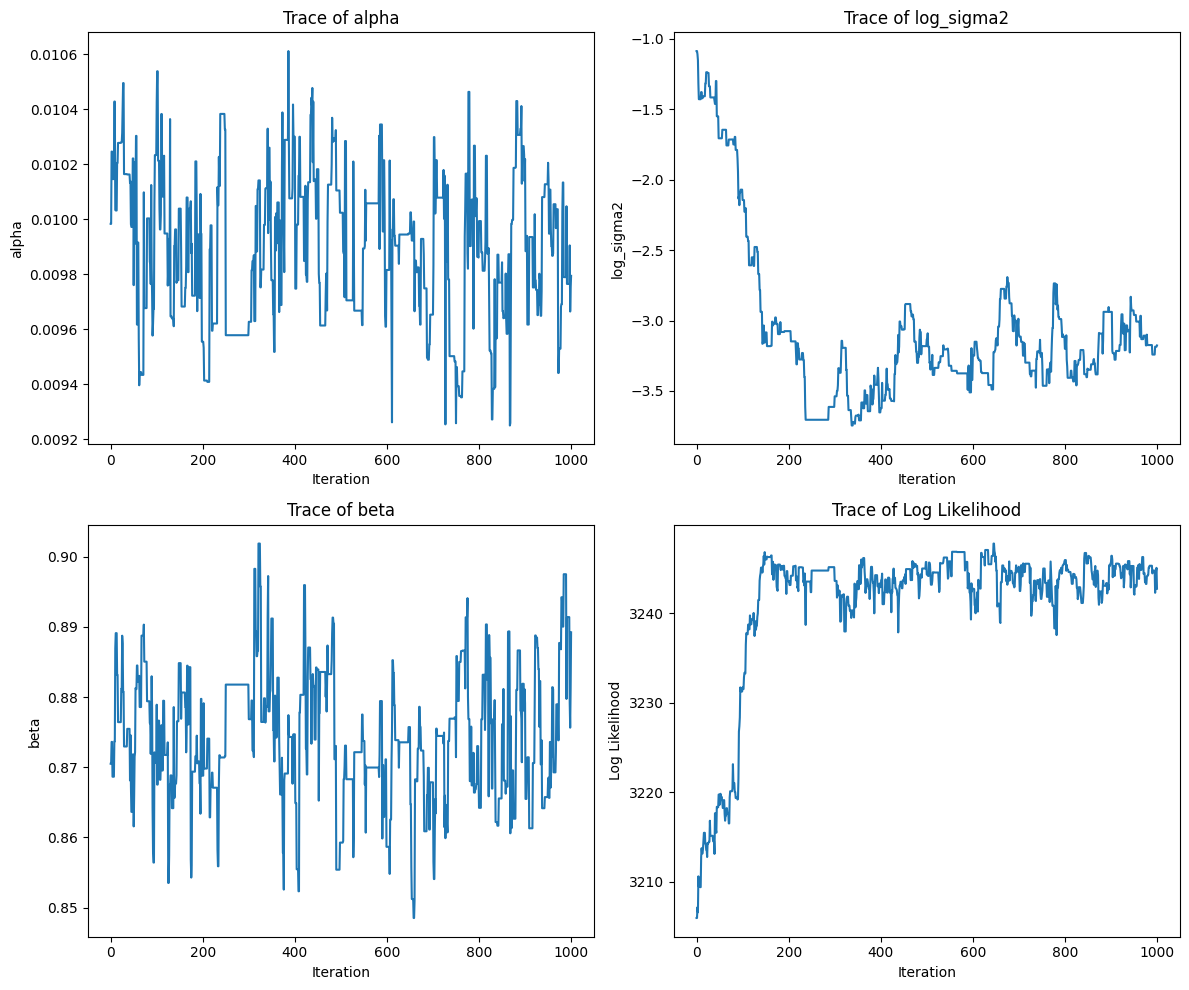

In [126]:
plot_trace(parameters_history_parametric, likelihood_history_parametric)

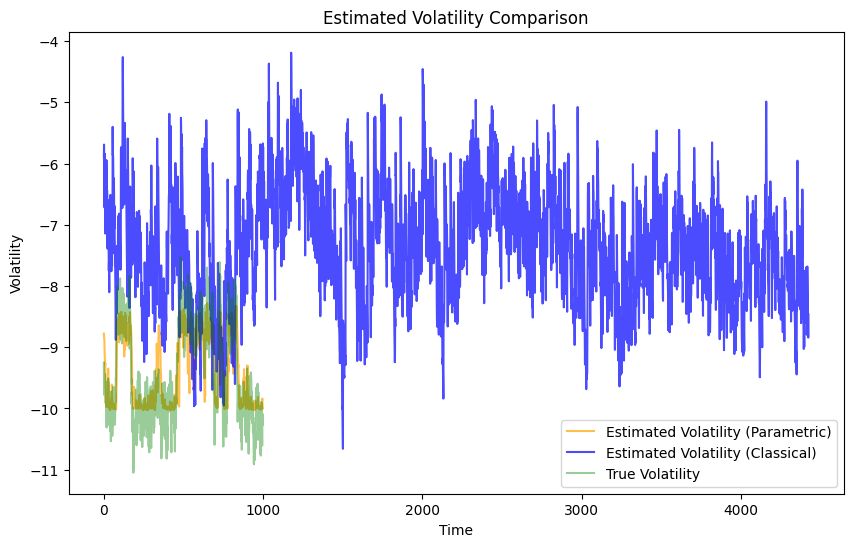

In [127]:
plt.figure(figsize=(10, 6))
plt.plot(h_hat_parametric, label='Estimated Volatility (Parametric)', color='orange', alpha=0.7)
plt.plot(h_hat_classical, label='Estimated Volatility (Classical)', color='blue', alpha=0.7)
plt.plot(h, label='True Volatility', color='green', alpha=0.4)
plt.title('Estimated Volatility Comparison')
plt.xlabel('Time')
plt.ylabel('Volatility')
plt.legend()
plt.show()

In [33]:
def plot_mh_comparison(parameters_classical, parameters_parametric,mh_simu=None):
    knots, g_hat = parameters_parametric['knots'], parameters_parametric['g']
    cubic_spline_func = CubicSpline(knots, g_hat, bc_type='natural')
    grid = np.linspace(knots[0], knots[-1], 100)
    spline_values = spline(cubic_spline_func, knots, grid)

    baisc_sv_fct = lambda h: parameters_classical["mu"]*(1-parameters_classical["phi"]) + parameters_classical["phi"]*h
    basic_sv = baisc_sv_fct(grid)
    if mh_simu :
        true_mh = mh_simu(grid)
    plt.figure(figsize=(10, 8))
    plt.subplot(2, 1, 1)
    plt.plot(grid, spline_values, label='Semi-parametric SV', color='purple')
    plt.plot(grid, basic_sv, label='Basic SV', color='green')
    plt.plot(grid, true_mh, label='True SV', color='red') if mh_simu else None
    plt.title('mh(.)')
    plt.xlabel('Knots')
    plt.ylabel('mh(.) Value')
    plt.legend()

    if mh_simu :
        plt.subplot(2, 1, 2)
        plt.plot(grid, abs(spline_values- true_mh), label='Error semi-parametric', color='purple')
        plt.plot(grid, abs(basic_sv - true_mh), label='Error basic SV', color='green')
        plt.title('Error in mh(.)')
        plt.xlabel('Knots')
        plt.ylabel('Error Value')
        plt.tight_layout()
        plt.legend()
        plt.show()
# plot_mh_comparison(parameters_classical, parameters_parametric)

In [76]:
# Integrated Mean Squared Error (IMSE)
def imse(mh_hat, mh_true, h):
    h_low,h_high = np.quantile(h, [0.05, 0.95])
    bound = int((h_high - h_low)/0.01)
    imse=0
    for i in range(bound):
        imse+= (mh_true(h_low + i * 0.01) - mh_hat(h_low + i * 0.01))**2 
    return imse*0.01

print(f"Semi Parametric IMSE: {imse(lambda h : spline(cubic_spline_func,knots,h), mh_simu, h_hat_parametric)}")
print(f"Basic SV IMSE: {imse(baisc_sv_fct, mh_simu, h_hat_classical)}")

Semi Parametric IMSE: 0.06451781747326113
Basic SV IMSE: 0.011354633773618672


essayer SMC ^2, plot ESS ?

In [18]:
import pandas as pd

btc = pd.read_csv('btc-usd-max.csv', index_col=False)
btc = btc.rename(columns={'snapped_at': 'Date', 'price': 'Close'})
btc['Returns'] = btc['Close'].pct_change()
btc['Log Returns'] = np.log(btc['Close']).diff()
btc = btc[btc["Date"]>="2014-01-01"]
btc = btc.dropna().reset_index()
btc.head()

,index,Date,Close,market_cap,total_volume,Returns,Log Returns
0,247,2014-01-01 00:00:00 UTC,767.74,9.358693e+09,23448600.0,0.016659,0.016521
1,248,2014-01-02 00:00:00 UTC,772.53,9.417083e+09,16837800.0,0.006239,0.006220
2,249,2014-01-03 00:00:00 UTC,825.47,1.006242e+10,54171500.0,0.068528,0.066282
3,250,2014-01-04 00:00:00 UTC,849.14,1.035095e+10,36344700.0,0.028675,0.028271
4,251,2014-01-05 00:00:00 UTC,919.41,1.120754e+10,62414600.0,0.082754,0.079508


/var/folders/f6/871w7hfs1sn9cs36ccfd_hpm0000gn/T/ipykernel_22516/2787280985.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


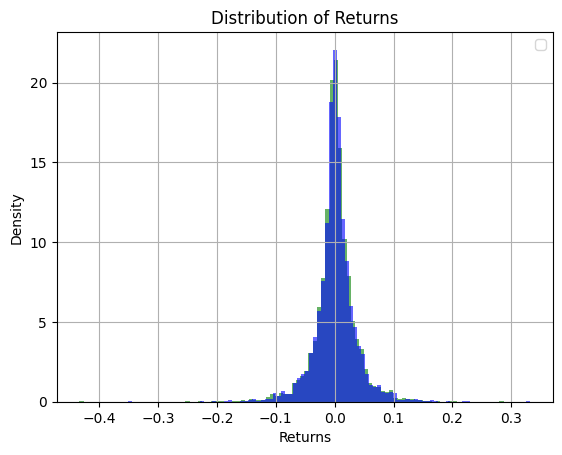

In [19]:
btc['Log Returns'].hist(bins=100, density=True, alpha=0.6, color='g')
btc['Returns'].hist(bins=100, density=True, alpha=0.6, color='b')
plt.xlabel('Returns')
plt.ylabel('Density')
plt.title('Distribution of Returns')
plt.legend()
plt.show()

<Axes: title={'center': 'Bitcoin Log Returns'}, xlabel='Date'>

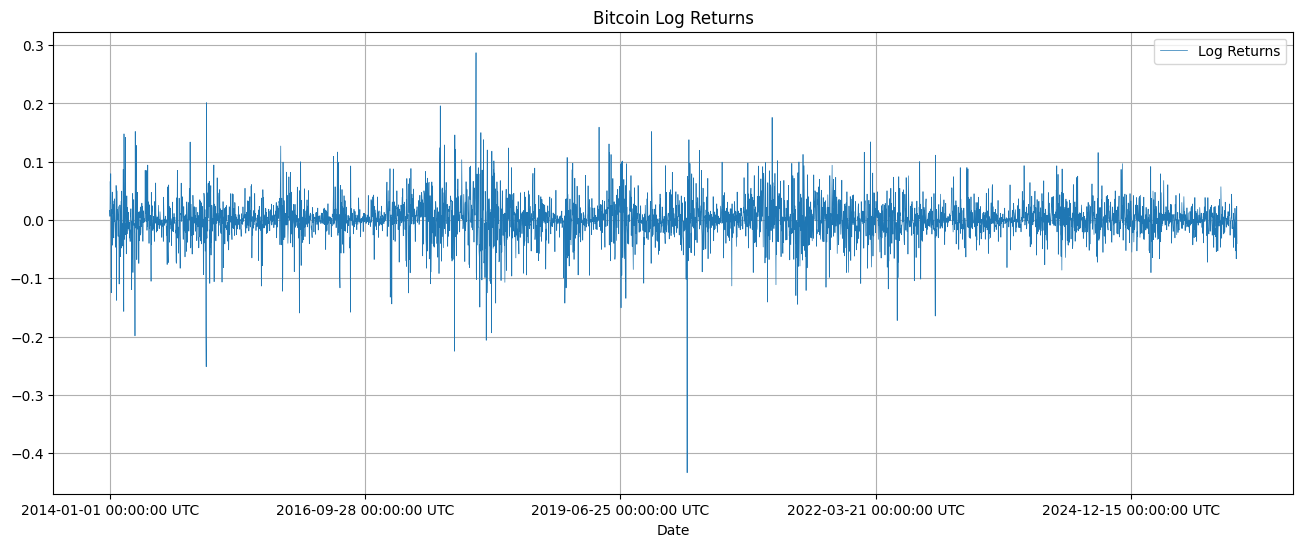

In [20]:
btc.plot(x='Date',y='Log Returns', kind='line', title='Bitcoin Log Returns', figsize=(16, 6), linewidth=0.5, grid=True)

In [21]:
btc_sample = btc_sample = btc[btc["Date"]<="2021-01-01"]
btc_sample.describe()

,index,Close,market_cap,total_volume,Returns,Log Returns
count,2556.000000,2556.000000,2.556000e+03,2.556000e+03,2556.000000,2556.000000
mean,1524.500000,4488.210503,7.877482e+10,8.324195e+09,0.002187,0.001425
std,737.997967,4757.006479,8.609924e+10,1.305575e+10,0.038872,0.039156
min,247.000000,172.147900,2.362640e+09,2.642092e+06,-0.351903,-0.433714
25%,885.750000,457.190750,6.640034e+09,1.057712e+08,-0.012433,-0.012511
50%,1524.500000,2607.041269,4.280918e+10,1.719966e+09,0.001815,0.001813
75%,2163.250000,8038.561958,1.406226e+11,1.453947e+10,0.017382,0.017232
max,2802.000000,28837.288529,5.359673e+11,8.140669e+10,0.332556,0.287099


 1: Log likelihood = 4737.180935948638, alpha = 0.01, mu = -6.494942789786193, phi = 0.5, log_sigma2 = -3
 101: Log likelihood = 5165.268891545537, alpha = 0.004656902658978046, mu = -6.67070594857441, phi = 0.6558255331393602, log_sigma2 = -0.19074451159711925
 201: Log likelihood = 5256.128444738468, alpha = 0.0013577290415954402, mu = -6.7573962360113615, phi = 0.8395667212041494, log_sigma2 = -0.5801545754802713
 301: Log likelihood = 5268.967885073918, alpha = 0.0012477665799558607, mu = -6.854391215102716, phi = 0.8732814064671746, log_sigma2 = -0.8173410434602201
 401: Log likelihood = 5268.967885073918, alpha = 0.0012477665799558607, mu = -6.854391215102716, phi = 0.8732814064671746, log_sigma2 = -0.8173410434602201
 501: Log likelihood = 5266.263877167674, alpha = 0.001358436300819003, mu = -6.831407075651395, phi = 0.8871661009427602, log_sigma2 = -0.9501264692911703
 601: Log likelihood = 5268.8850498688935, alpha = 0.0007628689788503803, mu = -6.954759141534202, phi = 0.883

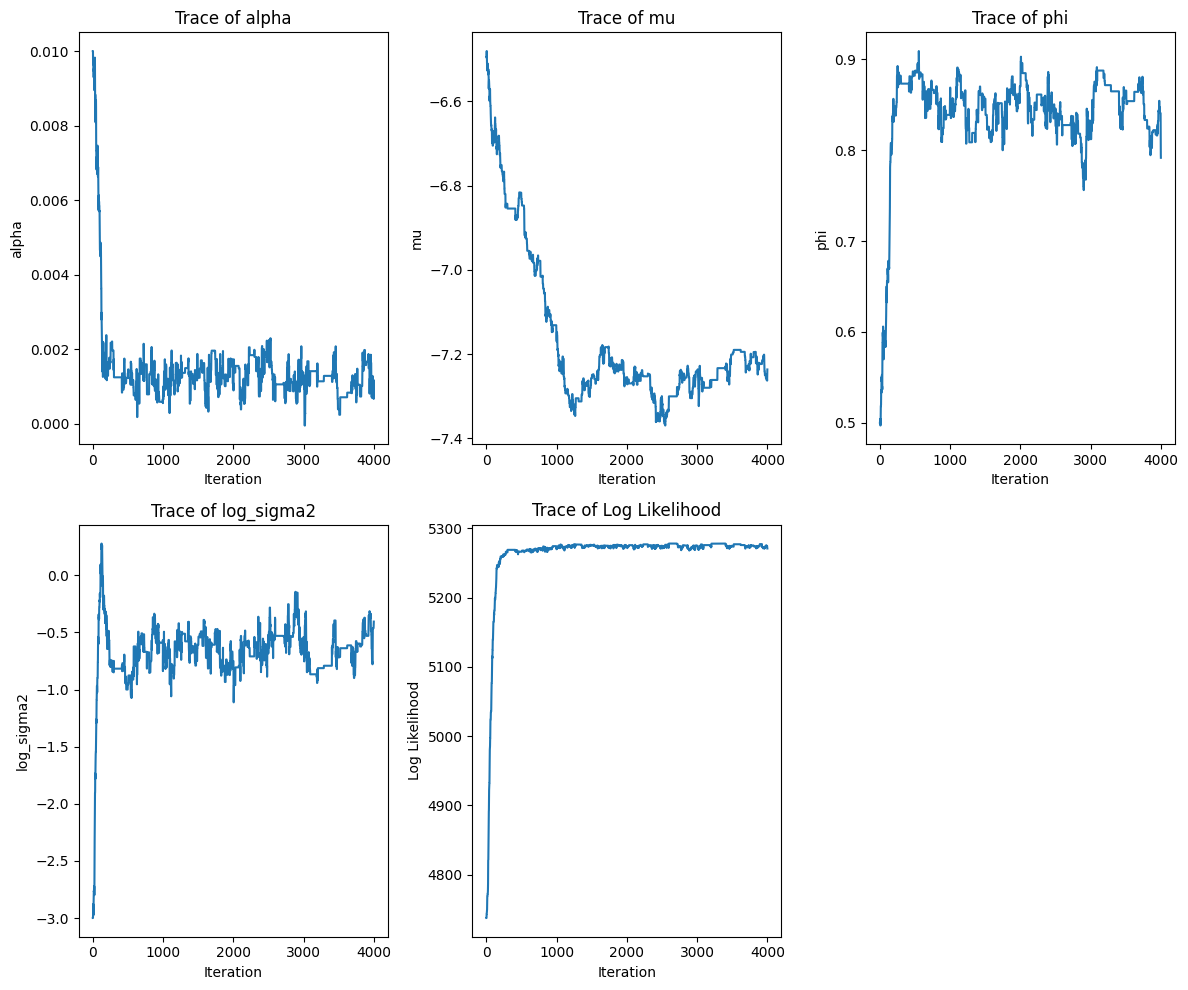

In [22]:


parameters_classical_btc, h_hat_classical_btc, parameters_history_classical_btc, likelihood_history_classical_btc = classical_sv_pmmh(btc_sample['Returns'],x=None, warmup_iterations=2000, iterations=2000)
plot_trace(parameters_history_classical_btc, likelihood_history_classical_btc)

Initializing using classical SV PMMH...
 1: Log likelihood = 4744.11909306159, alpha = 0.009842840556906613, mu = -6.489197247296049, phi = 0.5326571639620648, log_sigma2 = -3.038419845892873
 101: Log likelihood = 5128.300603977857, alpha = 0.00501654561167141, mu = -6.45284992605849, phi = 0.6444235944521086, log_sigma2 = 0.1991455647816933
 201: Log likelihood = 5250.634843367347, alpha = 0.0010810061192451652, mu = -6.55242792104372, phi = 0.8729506871306104, log_sigma2 = -0.8319736547255043
 301: Log likelihood = 5257.537979661147, alpha = 0.0006784849474119818, mu = -6.576927416381695, phi = 0.8882435555751004, log_sigma2 = -0.817841635299242
 1: Log likelihood = 5256.403028888073, alpha = 0.000894768228896035, log_sigma2 = -0.8079469342546217
 101: Log likelihood = 5261.955856451824, alpha = 0.0014238279667690241, log_sigma2 = -0.7483129422085675
 201: Log likelihood = 5269.606471763457, alpha = 0.0012993990616636869, log_sigma2 = -0.6677066877511589
 301: Log likelihood = 5269.

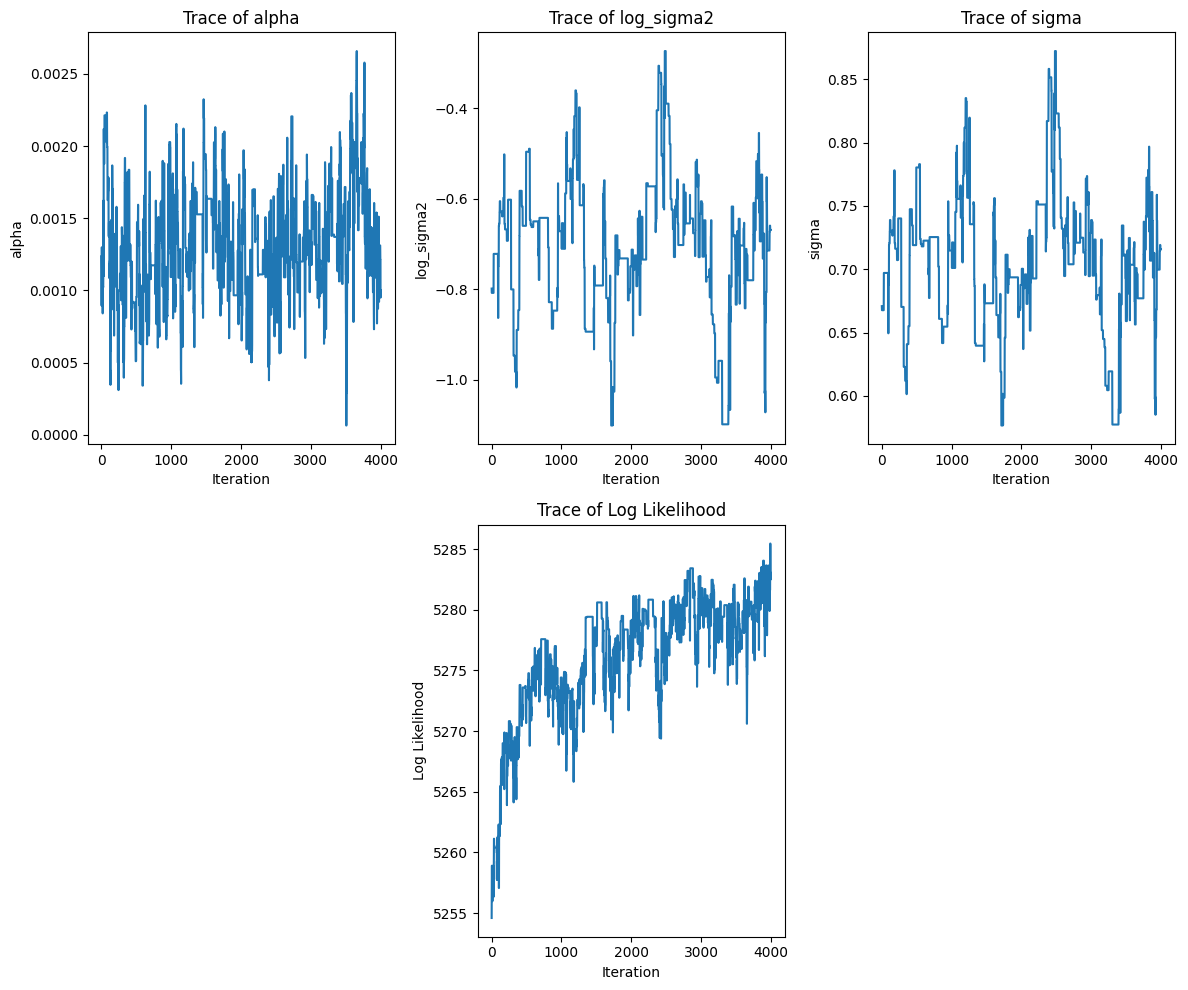

In [23]:
parameters_parametric_btc, h_hat_parametric_btc, parameters_history_parametric_btc, likelihood_history_parametric_btc, rates_btc= parametric_sv_pmmh(btc_sample['Returns'], sigma_e=0.2, warmup_iterations=2000, iterations=2000)
plot_trace(parameters_history_parametric_btc, likelihood_history_parametric_btc)

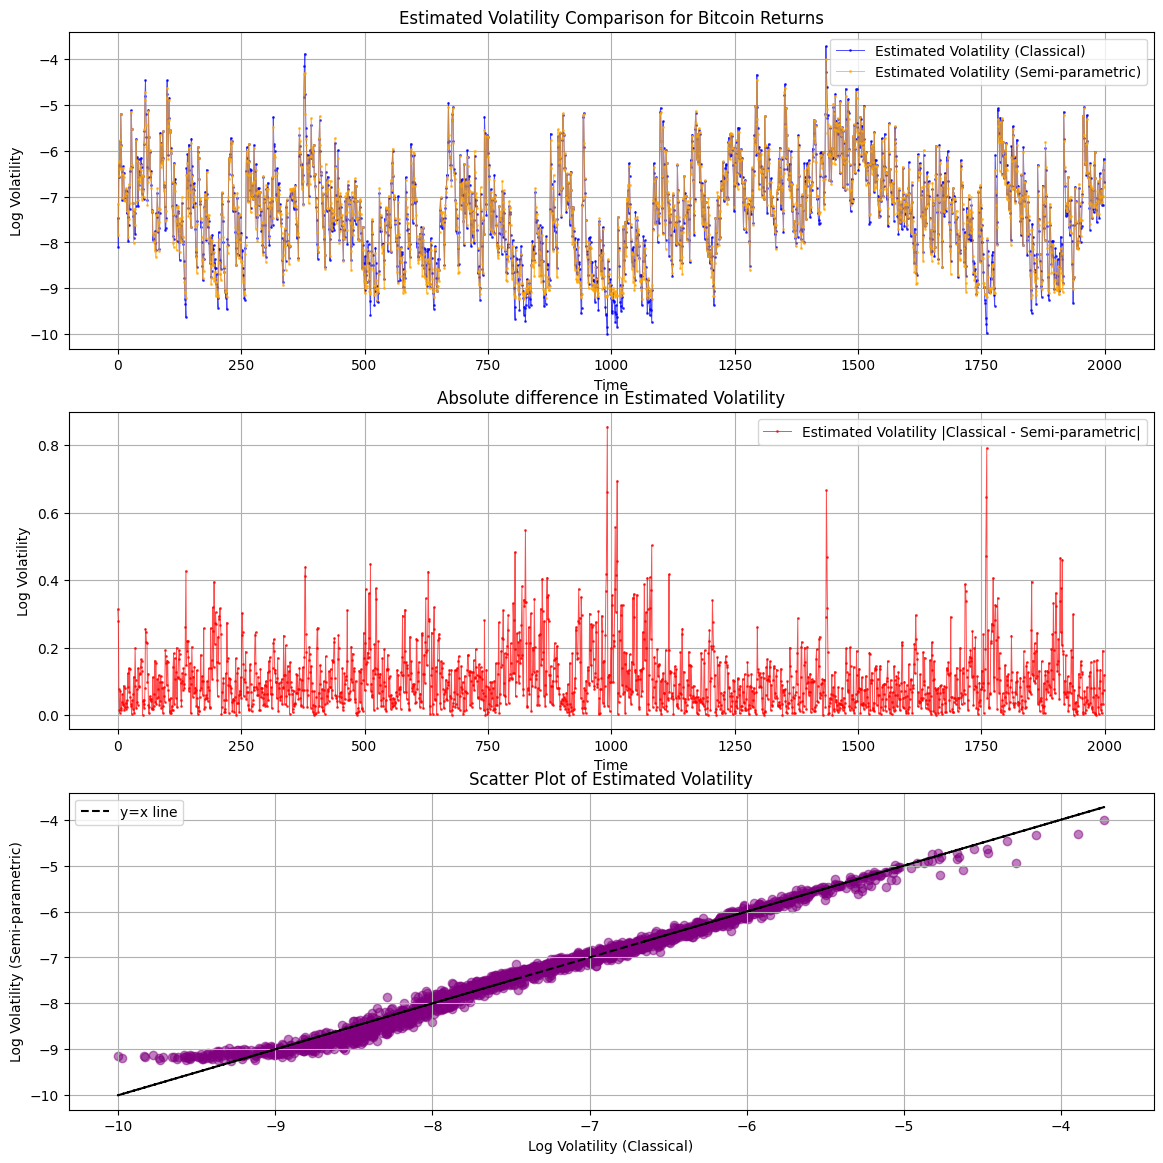

In [52]:
window_size = 2000
plt.figure(figsize=(14, 14))
plt.subplot(3,1,1)
plt.plot(h_hat_classical_btc[:window_size], label='Estimated Volatility (Classical)', color='blue', alpha=0.7, linewidth=0.7, marker='o',markersize=1)
plt.plot(h_hat_parametric_btc[:window_size], label='Estimated Volatility (Semi-parametric)', color='orange', alpha=0.7, linewidth=0.7, marker='o',markersize=1)
plt.title('Estimated Volatility Comparison for Bitcoin Returns')
plt.xlabel('Time')
plt.ylabel('Log Volatility')
plt.legend()
plt.grid()
plt.subplot(3,1,2)
plt.plot(abs(h_hat_classical_btc[:window_size]-h_hat_parametric_btc[:window_size]), label='Estimated Volatility |Classical - Semi-parametric|', color='red', alpha=0.7, linewidth=0.7, marker='o',markersize=1)
plt.title('Absolute difference in Estimated Volatility')
plt.xlabel('Time')
plt.ylabel('Log Volatility')
plt.legend()
plt.grid()
plt.subplot(3,1,3)
plt.scatter(h_hat_classical_btc[:window_size], h_hat_parametric_btc[:window_size], alpha=0.5, color='purple')
plt.plot(h_hat_classical_btc[:window_size], h_hat_classical_btc[:window_size], color='black', linestyle='--', label='y=x line')
plt.title('Scatter Plot of Estimated Volatility')
plt.xlabel('Log Volatility (Classical)')
plt.ylabel('Log Volatility (Semi-parametric)')
plt.legend()
plt.grid()
plt.show()

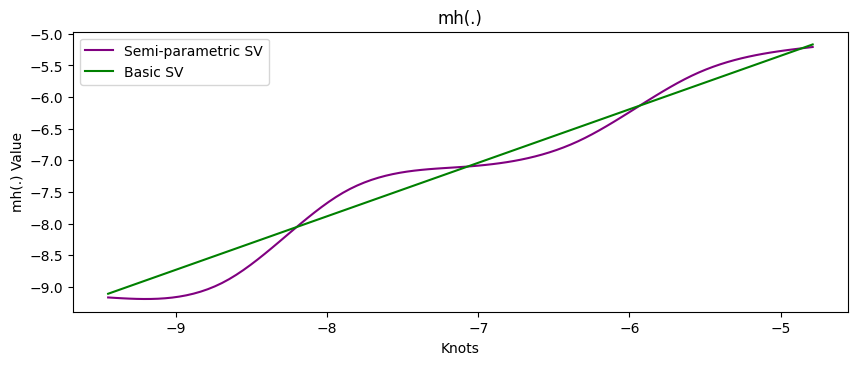

In [34]:
plot_mh_comparison(parameters_classical_btc, parameters_parametric_btc)

In [28]:
rates_btc, parameters_parametric_btc

((0.257, 0.06575),
 {'alpha': 0.0013377631488737485,
  'log_sigma2': -0.6971031298286559,
  'g': array([-9.16904241, -8.91118831, -7.51367484, -7.10709252, -6.70149112,
         -5.63714168, -5.20928406]),
  'knots': array([-9.44768973, -8.67113895, -7.89458817, -7.11803738, -6.3414866 ,
         -5.56493582, -4.78838504]),
  'initial': (-6.588780986196059, 1.4655654000579081),
  'sigma': 0.7081596863716847})